# Dataset EDA

Exploratory analysis of the graph data used in this repository.

This notebook:
- discovers the local `training`, `validation`, and `test` splits under `data/`
- inspects the raw `.npy` graph schema described in `data/README.md`
- computes event-level summary statistics on a configurable sample of events
- visualizes node, edge, PV, and label distributions
- compares the raw event representation with the homogeneous and heterogeneous dataset builders used by the repo

In [15]:
from __future__ import annotations

from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.style.use("ggplot")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)

In [16]:
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent

DATA_DIR = REPO_ROOT / "data"
SPLIT_DIRS = {
    "train": DATA_DIR / "training_dataset",
    "validation": DATA_DIR / "validation_dataset",
    "test": DATA_DIR / "test_dataset",
}

# Keep this small for quick iteration, or set to None to scan a full split.
MAX_EVENTS_PER_SPLIT = 500
RANDOM_SEED = 7
SAMPLE_EVENT_POSITION = 0

NODE_FEATURES = [
    "Ox", "Oy", "Oz",
    "px", "py", "pz",
    "PVmin_x", "PVmin_y", "PVmin_z",
    "q",
    "PVtrue_x", "PVtrue_y", "PVtrue_z",
]
# The raw edge-column ordering in the extracted `.npy` files does not line up cleanly
# with the human-readable descriptions in the repo docs, so the EDA keeps generic
# names and lets the observed distributions drive interpretation.
EDGE_FEATURES = ["edge_feature_0", "edge_feature_1", "edge_feature_2", "edge_feature_3"]
TARGET_CLASSES = ["lcag_0", "lcag_1", "lcag_2", "lcag_3"]

assert DATA_DIR.exists(), f"Could not find data directory at {DATA_DIR}"

In [17]:
def list_event_pairs(split_dir: Path) -> list[tuple[Path, Path]]:
    input_files = sorted(split_dir.glob("input_*.npy"), key=lambda p: int(p.stem.split("_")[-1]))
    pairs = []
    for input_path in input_files:
        target_path = split_dir / input_path.name.replace("input_", "target_")
        if target_path.exists():
            pairs.append((input_path, target_path))
    return pairs


def maybe_sample_pairs(pairs: list[tuple[Path, Path]], limit: int | None, seed: int = RANDOM_SEED) -> list[tuple[Path, Path]]:
    if limit is None or limit >= len(pairs):
        return pairs
    rng = np.random.default_rng(seed)
    indices = np.sort(rng.choice(len(pairs), size=limit, replace=False))
    return [pairs[i] for i in indices]


def load_event(pair: tuple[Path, Path]) -> tuple[dict, dict]:
    input_path, target_path = pair
    graph = np.load(input_path, allow_pickle=True).item()
    target = np.load(target_path, allow_pickle=True).item()
    return graph, target


def shape_or_type(value):
    if hasattr(value, "shape"):
        return tuple(value.shape)
    if isinstance(value, dict):
        return {k: shape_or_type(v) for k, v in value.items()}
    return type(value).__name__


def summarize_event(graph: dict, target: dict) -> dict:
    receivers = np.asarray(graph["receivers"])
    senders = np.asarray(graph["senders"])
    nodes = np.asarray(graph["nodes"])
    edges = np.asarray(graph["edges"])
    labels = np.asarray(target["edges"])

    selected_node_indices = np.unique(receivers) if receivers.size else np.array([], dtype=int)
    selected_nodes = nodes[selected_node_indices] if selected_node_indices.size else np.empty((0, nodes.shape[1]))
    true_pvs = selected_nodes[:, -3:] if selected_nodes.size else np.empty((0, 3))
    reco_pvs_min_ip = selected_nodes[:, 6:9] if selected_nodes.size else np.empty((0, 3))

    return {
        "n_raw_nodes": int(nodes.shape[0]),
        "n_selected_nodes": int(selected_nodes.shape[0]),
        "n_edges": int(edges.shape[0]),
        "n_globals": int(np.asarray(graph["globals"]).size),
        "n_true_pvs": int(np.unique(true_pvs, axis=0).shape[0]) if true_pvs.size else 0,
        "n_minip_pvs": int(np.unique(reco_pvs_min_ip, axis=0).shape[0]) if reco_pvs_min_ip.size else 0,
        "charge_mean": float(selected_nodes[:, 9].mean()) if selected_nodes.size else np.nan,
        "charge_abs_mean": float(np.abs(selected_nodes[:, 9]).mean()) if selected_nodes.size else np.nan,
        "class_0": int(labels[:, 0].sum()),
        "class_1": int(labels[:, 1].sum()),
        "class_2": int(labels[:, 2].sum()),
        "class_3": int(labels[:, 3].sum()),
        "empty_edge_set": bool(senders.size == 0 or receivers.size == 0),
    }


def build_split_summary(split_name: str, pairs: list[tuple[Path, Path]], limit: int | None = MAX_EVENTS_PER_SPLIT) -> tuple[pd.DataFrame, dict]:
    sampled_pairs = maybe_sample_pairs(pairs, limit)
    rows = []
    for pair in sampled_pairs:
        graph, target = load_event(pair)
        row = summarize_event(graph, target)
        row["event_id"] = int(pair[0].stem.split("_")[-1])
        row["split"] = split_name
        rows.append(row)
    event_df = pd.DataFrame(rows).sort_values("event_id").reset_index(drop=True)

    metadata = {
        "split": split_name,
        "total_events_available": len(pairs),
        "events_profiled": len(event_df),
        "sampling_limit": limit,
    }
    return event_df, metadata


def collect_feature_matrix(pairs: list[tuple[Path, Path]], value_getter, limit: int = 100) -> np.ndarray:
    matrices = []
    for pair in maybe_sample_pairs(pairs, limit):
        graph, target = load_event(pair)
        values = value_getter(graph, target)
        if values.size:
            matrices.append(values)
    if not matrices:
        return np.empty((0, 0))
    return np.vstack(matrices)

In [18]:
split_pairs = {name: list_event_pairs(path) for name, path in SPLIT_DIRS.items()}
pd.DataFrame(
    [{"split": name, "events": len(pairs), "path": str(SPLIT_DIRS[name])} for name, pairs in split_pairs.items()]
)

,split,events,path
0,train,39519,c:\UNI\4t\TFG\REPOS\particle-collision-event-r...
1,validation,9280,c:\UNI\4t\TFG\REPOS\particle-collision-event-r...
2,test,10000,c:\UNI\4t\TFG\REPOS\particle-collision-event-r...


## Raw Event Schema

The raw files are dictionaries stored as `input_<i>.npy` and `target_<i>.npy`. The next cell shows the shapes and available keys for one sample event.

In [19]:
sample_pair = split_pairs["train"][SAMPLE_EVENT_POSITION]
sample_graph, sample_target = load_event(sample_pair)

schema_rows = []
for key, value in sample_graph.items():
    schema_rows.append({"source": "input", "key": key, "shape_or_type": shape_or_type(value)})
for key, value in sample_target.items():
    schema_rows.append({"source": "target", "key": key, "shape_or_type": shape_or_type(value)})

pd.DataFrame(schema_rows)

,source,key,shape_or_type
0,input,nodes,"(147, 13)"
1,input,edges,"(18562, 4)"
2,input,senders,"(18562,)"
3,input,receivers,"(18562,)"
4,input,globals,"(1,)"
5,target,nodes,"(147, 1)"
6,target,edges,"(18562, 4)"
7,target,senders,"(18562,)"
8,target,receivers,"(18562,)"
9,target,globals,"(0,)"


In [20]:
sample_nodes = pd.DataFrame(sample_graph["nodes"], columns=NODE_FEATURES)
sample_edges = pd.DataFrame(sample_graph["edges"], columns=EDGE_FEATURES)
sample_labels = pd.DataFrame(sample_target["edges"], columns=TARGET_CLASSES)

display(sample_nodes.head())
display(sample_edges.head())
display(sample_labels.head())

,Ox,Oy,Oz,px,py,pz,PVmin_x,PVmin_y,PVmin_z,q,PVtrue_x,PVtrue_y,PVtrue_z
0,-1.412251,-0.051940,134.615387,-0.861690,-0.012191,8.712486,0.044789,-0.021947,120.004951,1.0,0.044789,-0.021947,120.004951
1,0.121107,1.615228,134.615387,0.046551,1.141893,10.120760,0.044789,-0.021947,120.004951,-1.0,0.044789,-0.021947,120.004951
2,0.098827,1.305732,134.615387,0.016593,0.363048,3.955429,0.044789,-0.021947,120.004951,1.0,0.044789,-0.021947,120.004951
3,2.354125,2.603539,134.615387,0.663889,0.760369,4.215454,0.044789,-0.021947,120.004951,1.0,0.044789,-0.021947,120.004951
4,-1.991455,3.103296,134.615387,-0.357071,0.542228,2.540234,0.044789,-0.021947,120.004951,1.0,0.044789,-0.021947,120.004951


,edge_feature_0,edge_feature_1,edge_feature_2,edge_feature_3
0,1.0,0.153426,2.261927,0.0
1,1.0,0.138449,2.028575,0.0
2,1.0,0.309565,4.605466,0.0
3,1.0,0.213631,3.203954,0.0
4,1.0,0.245561,3.610291,0.0


,lcag_0,lcag_1,lcag_2,lcag_3
0,1.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0


## Split-Level Event Statistics

By default the notebook profiles a random sample of `MAX_EVENTS_PER_SPLIT` events per split to keep runtime reasonable. Set that value to `None` if you want a full pass over the extracted dataset.

In [21]:
split_event_tables = {}
split_metadata = []

for split_name, pairs in split_pairs.items():
    event_df, metadata = build_split_summary(split_name, pairs, limit=MAX_EVENTS_PER_SPLIT)
    split_event_tables[split_name] = event_df
    split_metadata.append(metadata)

metadata_df = pd.DataFrame(split_metadata)
metadata_df

,split,total_events_available,events_profiled,sampling_limit
0,train,39519,500,500
1,validation,9280,500,500
2,test,10000,500,500


In [22]:
summary_df = (
    pd.concat(split_event_tables.values(), ignore_index=True)
    .groupby("split")
    .agg(
        events=("event_id", "count"),
        mean_selected_nodes=("n_selected_nodes", "mean"),
        median_selected_nodes=("n_selected_nodes", "median"),
        mean_edges=("n_edges", "mean"),
        median_edges=("n_edges", "median"),
        mean_true_pvs=("n_true_pvs", "mean"),
        mean_minip_pvs=("n_minip_pvs", "mean"),
        empty_events=("empty_edge_set", "sum"),
    )
    .round(2)
)
summary_df

,events,mean_selected_nodes,median_selected_nodes,mean_edges,median_edges,mean_true_pvs,mean_minip_pvs,empty_events
split,,,,,,,,
test,500,138.23,133.0,20289.88,15483.0,5.51,5.18,0
train,500,145.24,141.0,22349.18,17473.0,5.58,5.27,0
validation,500,141.06,132.0,20952.78,15507.0,5.66,5.38,0


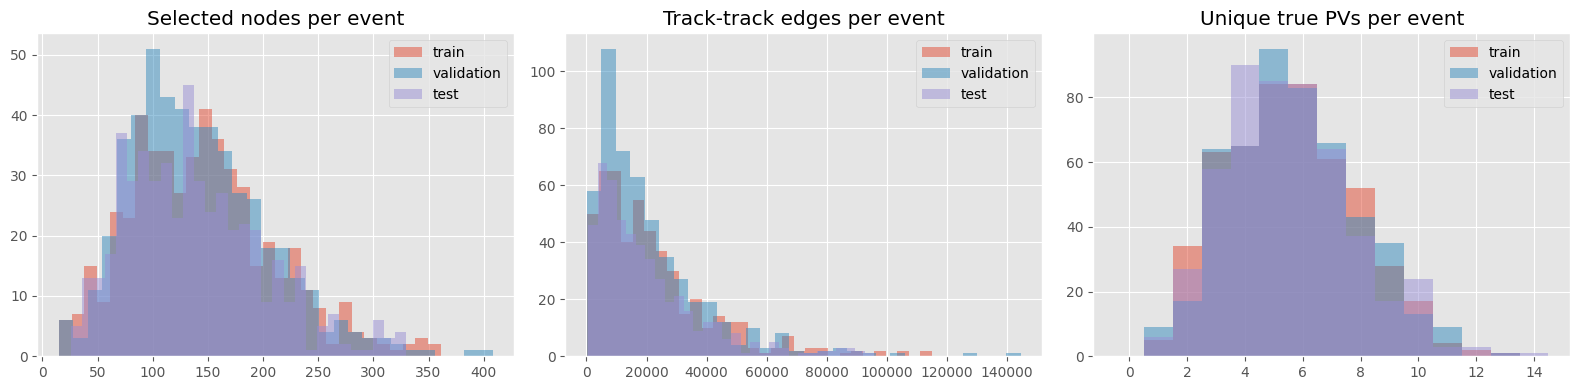

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for split_name, event_df in split_event_tables.items():
    axes[0].hist(event_df["n_selected_nodes"], bins=30, alpha=0.5, label=split_name)
    axes[1].hist(event_df["n_edges"], bins=30, alpha=0.5, label=split_name)
    axes[2].hist(event_df["n_true_pvs"], bins=np.arange(event_df["n_true_pvs"].max() + 2) - 0.5, alpha=0.5, label=split_name)

axes[0].set_title("Selected nodes per event")
axes[1].set_title("Track-track edges per event")
axes[2].set_title("Unique true PVs per event")
for ax in axes:
    ax.legend()
plt.tight_layout()

## Node Feature Distributions

The model loaders do not use every raw node column in the same way:
- the homogeneous dataset keeps the first 10 columns and stores the last 3 true PV coordinates separately
- the heterogeneous dataset uses `[Ox, Oy, Oz, px, py, pz, q]` for track features and derives PV nodes from the last 3 columns

In [24]:
node_matrix = collect_feature_matrix(
    split_pairs["train"],
    lambda graph, target: graph["nodes"],
    limit=min(100, len(split_pairs["train"])),
)
node_df = pd.DataFrame(node_matrix, columns=NODE_FEATURES)
node_df.describe().T

,count,mean,std,min,25%,50%,75%,max
Ox,13425.0,0.059007,5.493193,-117.702667,-0.375284,-0.009651,0.357423,140.252090
Oy,13425.0,-0.025023,5.311813,-122.501053,-0.363954,0.008450,0.367290,98.566948
Oz,13425.0,12.823378,110.771790,-269.230774,-57.692307,0.000000,76.923080,500.000000
px,13425.0,-0.001736,0.590793,-8.386051,-0.236356,-0.000789,0.229704,5.298269
py,13425.0,0.001323,0.574978,-8.021852,-0.229123,0.002198,0.233489,8.970975
pz,13425.0,10.603818,16.419668,0.042285,2.258816,5.218000,12.309219,328.913422
PVmin_x,13425.0,-0.001959,0.053086,-0.163219,-0.042945,-0.002947,0.034967,0.158420
PVmin_y,13425.0,0.000150,0.050217,-0.161543,-0.036454,0.002311,0.035574,0.154238
PVmin_z,13425.0,-6.512727,97.842850,-275.781891,-73.230156,-8.781606,59.512096,365.392181
q,13425.0,0.005736,1.000021,-1.000000,-1.000000,1.000000,1.000000,1.000000


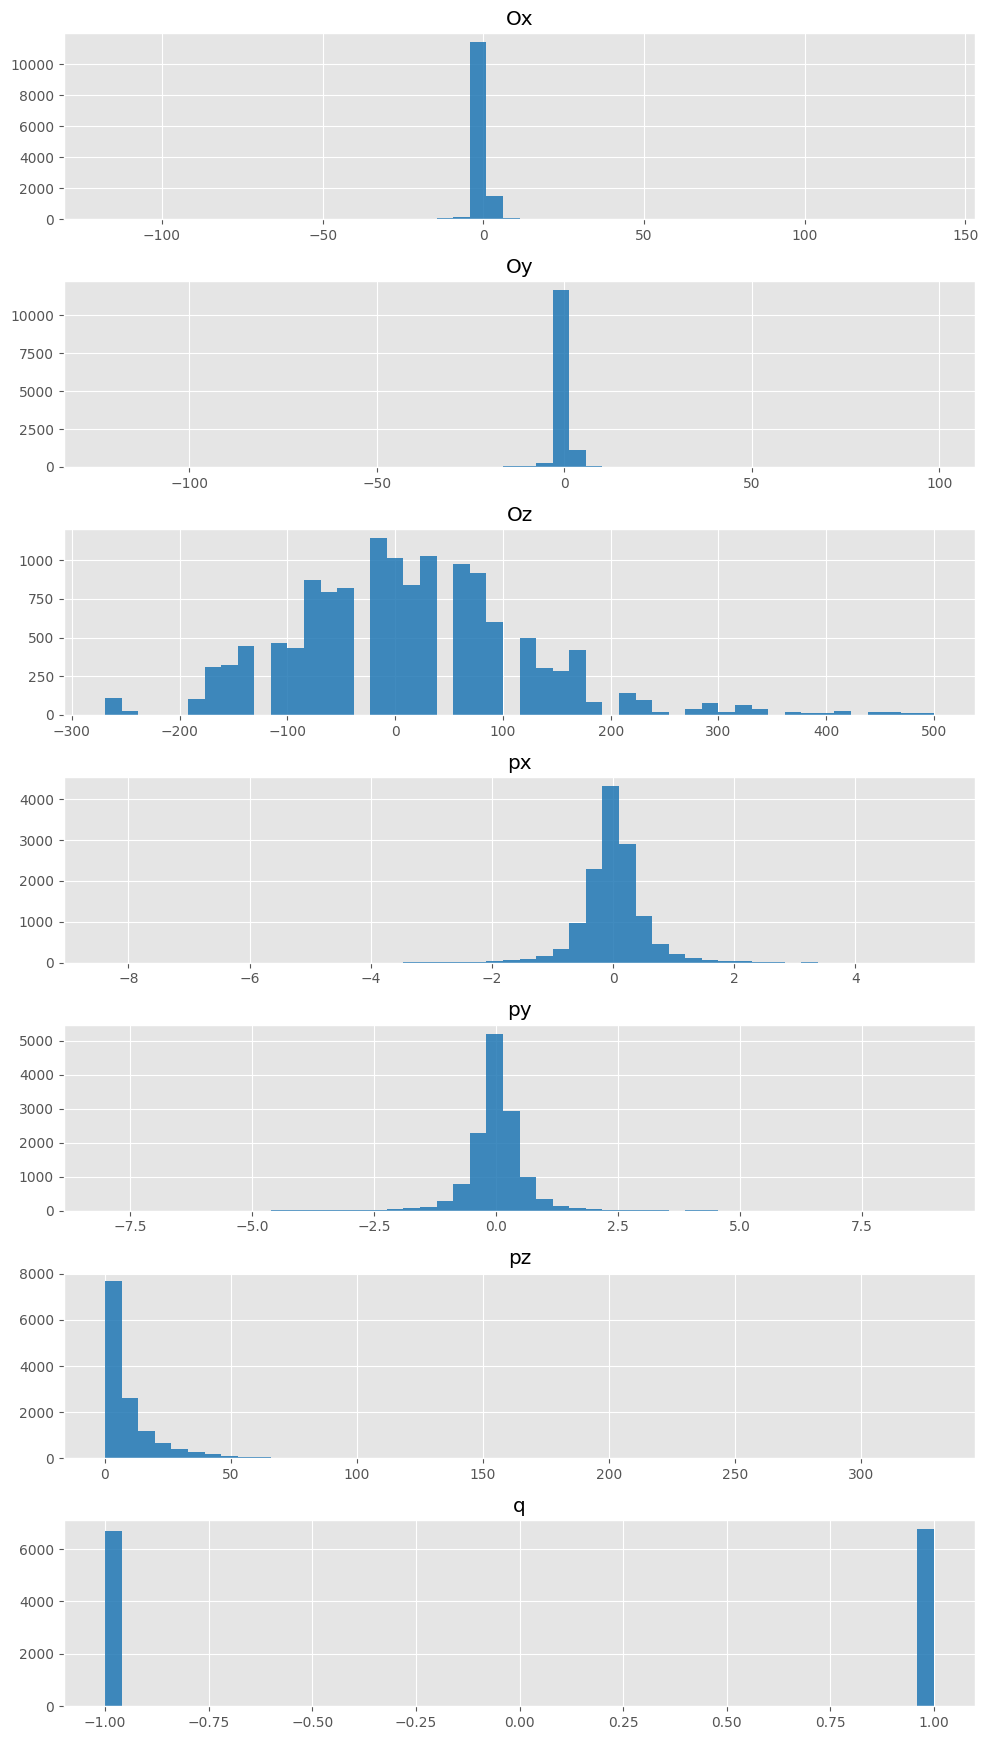

In [25]:
plot_columns = ["Ox", "Oy", "Oz", "px", "py", "pz", "q"]
fig, axes = plt.subplots(len(plot_columns), 1, figsize=(10, 2.5 * len(plot_columns)))
for ax, column in zip(axes, plot_columns):
    ax.hist(node_df[column], bins=50, color="#1f77b4", alpha=0.85)
    ax.set_title(column)
plt.tight_layout()

## Edge Features And LCAG Targets

The raw edge arrays clearly contain a mix of discrete and continuous features. Since the column order in the saved arrays is not fully consistent with the prose documentation, this section keeps generic edge feature names and shows their observed ranges directly.

In [26]:
edge_matrix = collect_feature_matrix(
    split_pairs["train"],
    lambda graph, target: graph["edges"],
    limit=min(100, len(split_pairs["train"])),
)
label_matrix = collect_feature_matrix(
    split_pairs["train"],
    lambda graph, target: target["edges"],
    limit=min(100, len(split_pairs["train"])),
)

edge_df = pd.DataFrame(edge_matrix, columns=EDGE_FEATURES)
label_df = pd.DataFrame(label_matrix, columns=TARGET_CLASSES)

display(edge_df.describe().T)
display(edge_df.nunique().rename("n_unique").to_frame())
display((label_df.sum().rename("count").to_frame().assign(fraction=lambda df: df["count"] / df["count"].sum())).round(4))

,count,mean,std,min,25%,50%,75%,max
edge_feature_0,1918836.0,0.298194,0.457465,0.00000,0.000000,0.000000,1.000000,1.000000
edge_feature_1,1918836.0,0.134186,0.079247,0.00000,0.069709,0.124137,0.190645,0.587419
edge_feature_2,1918836.0,7.283581,12.113812,0.00028,1.434046,3.285733,7.751146,201.738968
edge_feature_3,1918836.0,5.532219,136.130142,-750.00000,-57.692307,0.000000,57.692310,673.076904


,n_unique
edge_feature_0,2
edge_feature_1,429968
edge_feature_2,950829
edge_feature_3,172


,count,fraction
lcag_0,1916983.875,0.9990
lcag_1,454.000,0.0002
lcag_2,1234.000,0.0006
lcag_3,164.000,0.0001


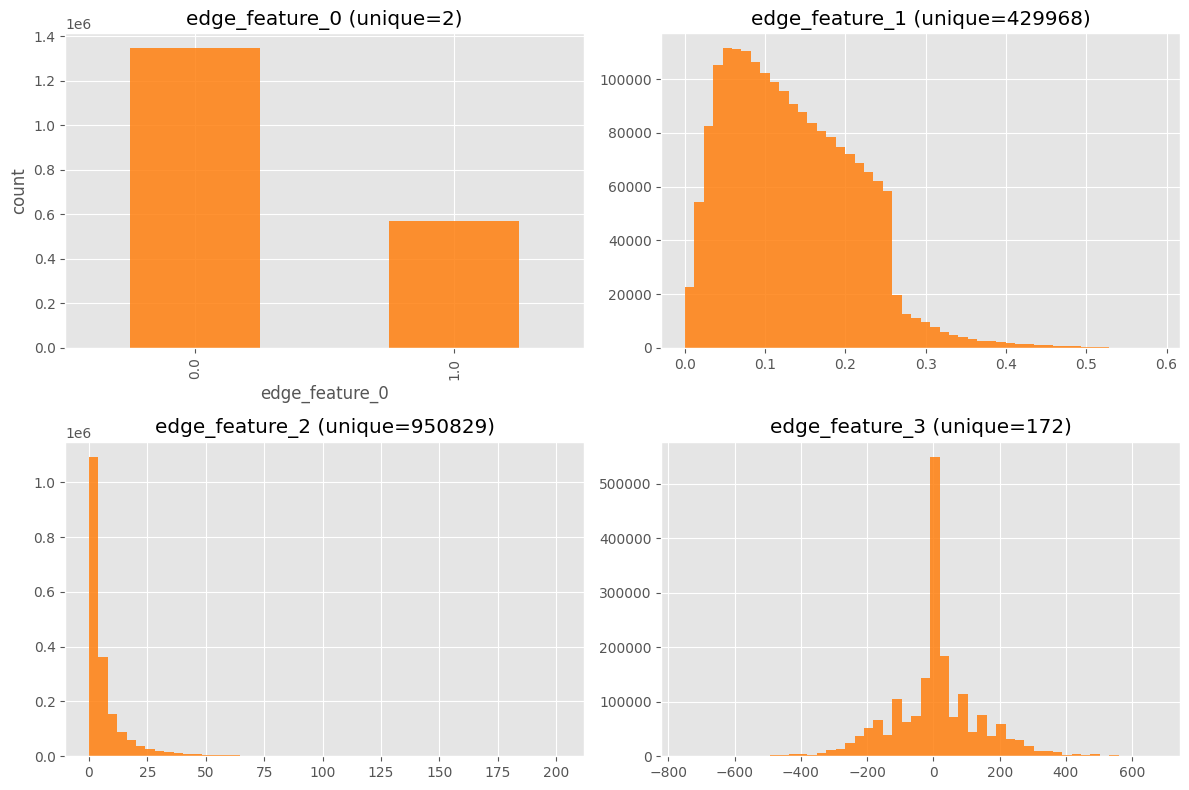

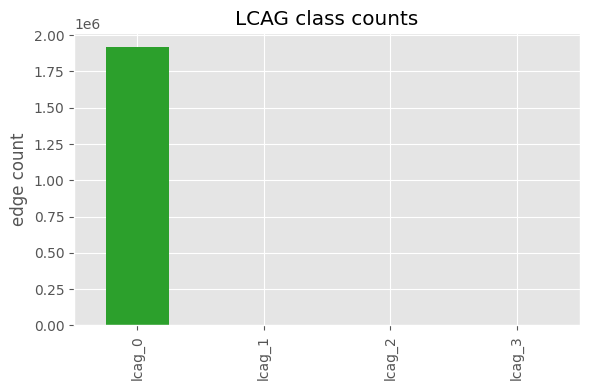

In [27]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, column in zip(axes.ravel(), EDGE_FEATURES):
    nunique = edge_df[column].nunique()
    if nunique <= 10:
        edge_df[column].value_counts().sort_index().plot(kind="bar", ax=ax, color="#ff7f0e", alpha=0.85)
        ax.set_ylabel("count")
    else:
        ax.hist(edge_df[column], bins=50, color="#ff7f0e", alpha=0.85)
    ax.set_title(f"{column} (unique={nunique})")
plt.tight_layout()

plt.figure(figsize=(6, 4))
label_df.sum().plot(kind="bar", color="#2ca02c")
plt.title("LCAG class counts")
plt.ylabel("edge count")
plt.tight_layout()

## Event-Level Geometry View

This is a lightweight spatial view of one event. Track origins are colored by the true reconstructed PV assignment stored in the last three node columns.

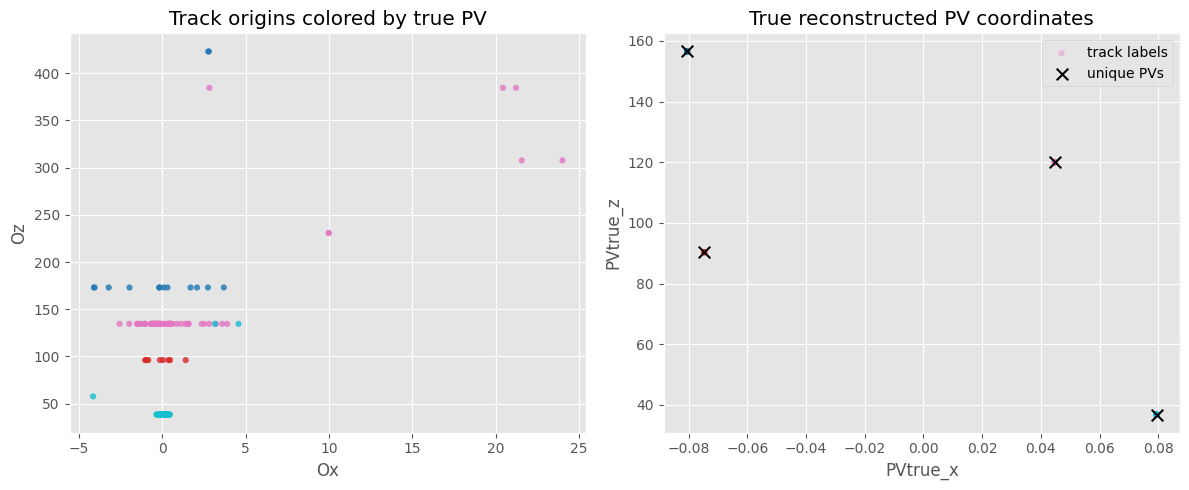

In [28]:
selected_indices = np.unique(sample_graph["receivers"])
selected_nodes = sample_graph["nodes"][selected_indices]
track_xyz = selected_nodes[:, :3]
true_pv_xyz = selected_nodes[:, -3:]

unique_true_pvs, pv_codes = np.unique(true_pv_xyz, axis=0, return_inverse=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(track_xyz[:, 0], track_xyz[:, 2], c=pv_codes, s=15, cmap="tab10", alpha=0.8)
axes[0].set_xlabel("Ox")
axes[0].set_ylabel("Oz")
axes[0].set_title("Track origins colored by true PV")

axes[1].scatter(true_pv_xyz[:, 0], true_pv_xyz[:, 2], c=pv_codes, s=15, cmap="tab10", alpha=0.35, label="track labels")
axes[1].scatter(unique_true_pvs[:, 0], unique_true_pvs[:, 2], c="black", s=70, marker="x", label="unique PVs")
axes[1].set_xlabel("PVtrue_x")
axes[1].set_ylabel("PVtrue_z")
axes[1].set_title("True reconstructed PV coordinates")
axes[1].legend()

plt.tight_layout()

## How Repo Dataset Builders Transform A Raw Event

In [32]:
try:
    import sys

    if str(REPO_ROOT) not in sys.path:
        sys.path.append(str(REPO_ROOT))

    from wmpgnn.datasets.graph_dataset import CustomDataset
    from wmpgnn.datasets.hetero_graph_dataset import CustomHeteroDataset

    input_path, target_path = sample_pair
    homog_event = CustomDataset([str(input_path)], [str(target_path)]).get()[0]
    hetero_event = CustomHeteroDataset([str(input_path)], [str(target_path)]).get()[0]

    transformed_summary = pd.DataFrame([
        {
            "view": "homogeneous",
            "node_feature_shape": tuple(homog_event.nodes.shape),
            "edge_feature_shape": tuple(homog_event.edges.shape),
            "labels_shape": tuple(homog_event.y.shape),
            "num_nodes": int(homog_event.num_nodes),
            "num_edges": int(homog_event.num_edges),
        },
        {
            "view": "heterogeneous",
            "node_feature_shape": {
                "tracks": tuple(hetero_event['tracks'].x.shape),
                "pvs": tuple(hetero_event['pvs'].x.shape),
                "globals": tuple(hetero_event['globals'].x.shape),
            },
            "edge_feature_shape": {
                "tracks_tracks": tuple(hetero_event['tracks', 'tracks'].edges.shape),
                "tracks_pvs": tuple(hetero_event['tracks', 'pvs'].edges.shape),
            },
            "labels_shape": {
                "tracks_tracks": tuple(hetero_event['tracks', 'tracks'].y.shape),
                "tracks_pvs": tuple(hetero_event['tracks', 'pvs'].y.shape),
            },
            "num_nodes": {
                "tracks": int(hetero_event['tracks'].num_nodes),
                "pvs": int(hetero_event['pvs'].num_nodes),
            },
            "num_edges": {
                "tracks_tracks": int(hetero_event['tracks', 'tracks'].edge_index.shape[1]),
                "tracks_pvs": int(hetero_event['tracks', 'pvs'].edge_index.shape[1]),
            },
        },
    ])

    transformed_summary
except Exception as exc:
    print("Dataset transformation preview skipped.")
    print(type(exc).__name__, exc)

## Notes

- `graph_dataset.py` remaps nodes using `np.unique(receivers)` before creating the homogeneous `Data` object.
- `hetero_graph_dataset.py` derives PV nodes from the last three raw node columns and creates all track-PV pairs as a bipartite edge set.
- If you want a more exhaustive EDA pass, increase `MAX_EVENTS_PER_SPLIT` or set it to `None` and rerun the notebook.
- If you want model-focused analysis next, natural follow-ups are class imbalance by split, feature correlations, and per-event memory/runtime estimates.